# День 08. Упражнение 01
# Бинарный классификатор. SVM. Дерево решений

## 0. Импорты

In [178]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

## 1. Предобработка и визуализация логистической регрессии

Прочитай файл am_pm.csv в DataFrame из предыдущего упражнения.

Прочитай файл am_pm.csv в DataFrame из предыдущего упражнения.
1. Построй график, где по оси x — am, по оси y — pm, точки — это дни, цвет зависит от целевой переменной.
2. Добавь на график границу решений логистической регрессии.
3. Построй тот же график (с границей), но на этот раз цвет должен зависеть от предсказаний.

Теперь тебе должно быть понятно, как работает логистическая регрессия.


In [151]:
df = pd.read_csv("../data/am_pm.csv")
df.head()

,date,am,pm,target,predict
0,2020-04-17,21,2,working day,weekend
1,2020-04-18,1,68,weekend,working day
2,2020-04-19,18,15,weekend,working day
3,2020-04-20,2,23,working day,working day
4,2020-04-21,0,25,working day,working day


In [152]:
X = df[["am","pm"]]
y = df["target"]
model = LogisticRegression(random_state=21, fit_intercept=False)
model.fit(X,y)
y_predict = model.predict(X)
ac_score = accuracy_score(y,y_predict)
ac_score


0.6285714285714286

In [153]:
# Для того чтобы добавить границу лог. регрессии нам нужно поработать с коэффициентами
c_am, c_pm = model.coef_[0]

# Выбираем крайние диапазоны am и pm чтобы линия прошла через них
am_values = pd.Series([df["am"].min(), df["am"].max()]) 
k = -(c_am/c_pm) # Наклон прямой
pm_values = k * am_values



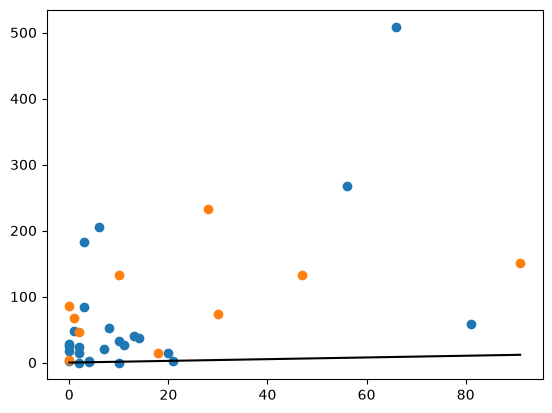

In [154]:
working_day = df.loc[df["target"] == 'working day']
weekend_day = df.loc[df["target"] == 'weekend']
plt.scatter(working_day["am"], working_day["pm"], label="working day")
plt.scatter(weekend_day["am"], weekend_day["pm"], label="weekend")
#Рисуем границу логистической регрессии
plt.plot(
    am_values, pm_values,
    color="black"
)

In [155]:
# Строим график с той же границей, но с различным цветом

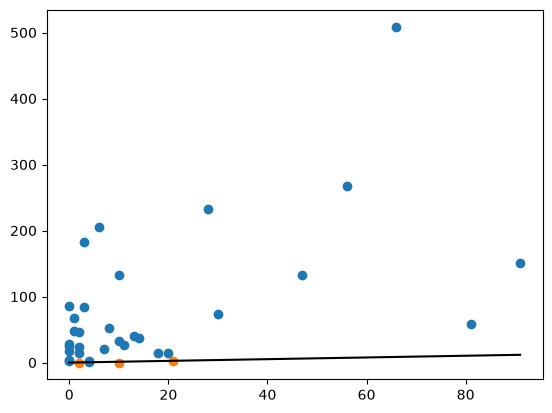

In [156]:
working_day = df.loc[df["predict"] == 'working day']
weekend_day = df.loc[df["predict"] == 'weekend']
plt.scatter(working_day["am"], working_day["pm"], label="working day")
plt.scatter(weekend_day["am"], weekend_day["pm"], label="weekend")
#Рисуем границу логистической регрессии
plt.plot(
    am_values, pm_values,
    color="black"
)

## 2. Стандартизация и логистическая регрессия

Линейные модели чувствительны к масштабу переменных. Масштабирование признаков помогает модели проще находить оптимальное решение.

1. Применись StandardScaler к X и обучи логистическую регрессию снова с теми же параметрами.
2. Вычисли accuracy для новой модели. Стала ли она лучше наивного классификатора, предсказывающего самый частый класс?
3. Построй описанные выше графики, но уже для новой модели.

In [157]:
# Применяем вычисление параметров
scaler = StandardScaler()
scaled_X = scaler.fit_transform(X)
scaled_X


array([[ 0.20069005, -0.71990365],
       [-0.65591383, -0.07182203],
       [ 0.07219947, -0.59225121],
       [-0.61308363, -0.51369586],
       [-0.69874402, -0.49405703],
       [-0.69874402, -0.46459877],
       [-0.27044208, -0.41550168],
       [-0.61308363, -0.60207063],
       [ 0.5861618 , -0.01290552],
       [ 0.50050141,  1.54838202],
       [-0.52742324, -0.71990365],
       [-0.52742324, -0.72972307],
       [-0.69874402, -0.57261237],
       [-0.1419515 , -0.34676575],
       [-0.35610247, -0.22893273],
       [ 3.19880362,  0.7431897 ],
       [ 1.31427509,  0.56644017],
       [-0.22761189, -0.48423761],
       [ 2.77050168, -0.17001622],
       [-0.61308363, -0.73954249],
       [-0.09912131, -0.36640459],
       [-0.57025344,  0.08528866],
       [-0.69874402,  0.1049275 ],
       [-0.27044208,  0.56644017],
       [-0.57025344,  1.05741109],
       [ 1.69974683,  1.88224224],
       [-0.44176286,  1.2734383 ],
       [ 2.12804877,  4.25854152],
       [-0.27044208,

In [158]:
#Обучем модель по преобразованным признакам
model.fit(scaled_X, y)
y_sc_predict = model.predict(scaled_X)
ac_sc_score = accuracy_score(y, y_sc_predict)
ac_sc_score

0.7428571428571429

Да, она стала лучше классификатора, который предсказывает самый частый класс. Точность повысилась

In [159]:
# Готовим данные для графика
sc_df = pd.DataFrame(scaled_X, columns=["am","pm"])
sc_df["target"] = df["target"]
sc_df

,am,pm,target
0,0.200690,-0.719904,working day
1,-0.655914,-0.071822,weekend
2,0.072199,-0.592251,weekend
3,-0.613084,-0.513696,working day
4,-0.698744,-0.494057,working day
5,-0.698744,-0.464599,working day
6,-0.270442,-0.415502,working day
7,-0.613084,-0.602071,working day
8,0.586162,-0.012906,weekend
9,0.500501,1.548382,weekend


In [160]:
# Для того чтобы добавить границу лог. регрессии нам нужно поработать с коэффициентами
c_am, c_pm = model.coef_[0]

# Выбираем крайние диапазоны am и pm чтобы линия прошла через них
am_values = pd.Series([sc_df["am"].min(), sc_df["am"].max()]) 
k = -(c_am/c_pm) # Наклон прямой
pm_values = k * am_values

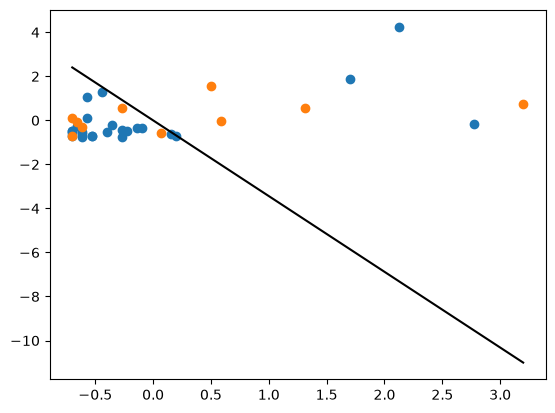

In [161]:
working_day = sc_df.loc[sc_df["target"] == 'working day']
weekend_day = sc_df.loc[sc_df["target"] == 'weekend']
plt.scatter(working_day["am"], working_day["pm"], label="working day")
plt.scatter(weekend_day["am"], weekend_day["pm"], label="weekend")
#Рисуем границу логистической регрессии
plt.plot(
    am_values, pm_values,
    color="black"
)

In [162]:
#Добавляем предсказанные дни в новый датафрейм
sc_df["predict"] = y_sc_predict
sc_df

,am,pm,target,predict
0,0.200690,-0.719904,working day,working day
1,-0.655914,-0.071822,weekend,working day
2,0.072199,-0.592251,weekend,working day
3,-0.613084,-0.513696,working day,working day
4,-0.698744,-0.494057,working day,working day
5,-0.698744,-0.464599,working day,working day
6,-0.270442,-0.415502,working day,working day
7,-0.613084,-0.602071,working day,working day
8,0.586162,-0.012906,weekend,weekend
9,0.500501,1.548382,weekend,weekend


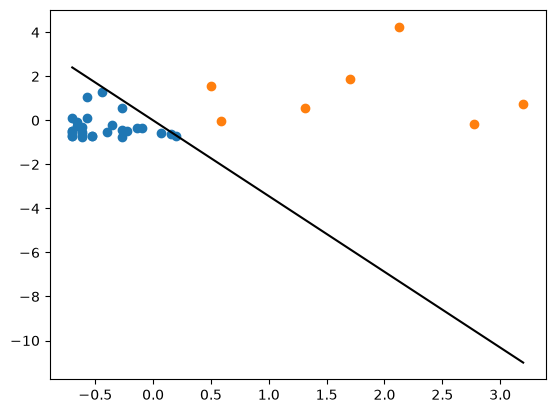

In [163]:
working_day = sc_df.loc[sc_df["predict"] == 'working day']
weekend_day = sc_df.loc[sc_df["predict"] == 'weekend']
plt.scatter(working_day["am"], working_day["pm"], label="working day")
plt.scatter(weekend_day["am"], weekend_day["pm"], label="weekend")
#Рисуем границу логистической регрессии
plt.plot(
    am_values, pm_values,
    color="black"
)

## 3. SVM

1. Применись модель SVC к масштабированному DataFrame с параметрами probability=True, random_state=21.
2. Вычисли accuracy.
3. Попробуй разные ядра и найди то, которое дает наилучшую точность.
4. Построй оба графика снова с границей решений, чтобы увидеть, как работает этот алгоритм.

In [164]:
model_svc = SVC(probability=True, random_state=21)
model_svc.fit(sc_df[["am", "pm"]], sc_df["target"])
svc_pred = model_svc.predict(sc_df[["am","pm"]])
svm_pred_df = pd.DataFrame(svc_pred, columns=["predict"])
svm_acc = accuracy_score(sc_df["target"], svm_pred_df["predict"])
svm_acc


/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.7428571428571429

In [165]:
#Перебираем другие ядра
model_svc_1 = SVC(probability=True, random_state=21, kernel="linear")
model_svc_1.fit(sc_df[["am", "pm"]], sc_df["target"])
svc_pred = model_svc_1.predict(sc_df[["am","pm"]])
svm_acc = accuracy_score(sc_df["target"], svc_pred)
svm_acc


/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.7142857142857143

In [166]:
model_svc_2 = SVC(probability=True, random_state=21, kernel="poly")
model_svc_2.fit(sc_df[["am", "pm"]], sc_df["target"])
svc_pred = model_svc_2.predict(sc_df[["am","pm"]])
svm_acc = accuracy_score(sc_df["target"], svc_pred)
svm_acc

/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.7428571428571429

In [167]:
model_svc_3 = SVC(probability=True, random_state=21, kernel="sigmoid")
model_svc_3.fit(sc_df[["am", "pm"]], sc_df["target"])
svc_pred = model_svc_3.predict(sc_df[["am","pm"]])
svm_acc = accuracy_score(sc_df["target"], svc_pred)
svm_acc

/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.6857142857142857

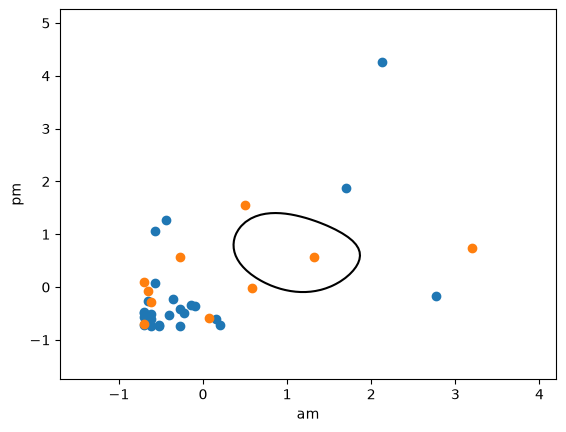

In [168]:
# График для модели без предсказаний
svm_pred_df["am"] = sc_df["am"]
svm_pred_df["pm"] = sc_df["pm"]
svm_pred_df["target"] = df["target"]
DecisionBoundaryDisplay.from_estimator(
    model_svc,
    svm_pred_df[["am", "pm"]],
    response_method="decision_function",
    plot_method="contour",
    levels=[0],
    colors="black",
    ax=plt.gca()
)
working_day = svm_pred_df.loc[svm_pred_df["target"] == 'working day']
weekend_day = svm_pred_df.loc[svm_pred_df["target"] == 'weekend']
plt.scatter(working_day["am"], working_day["pm"], label="working day")
plt.scatter(weekend_day["am"], weekend_day["pm"], label="weekend")

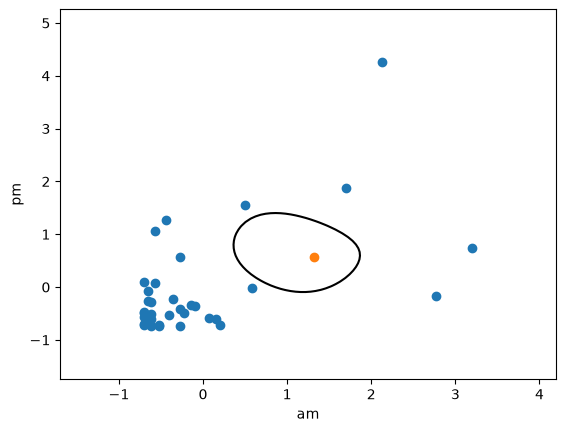

In [169]:
#График для модели с предсказаниями
DecisionBoundaryDisplay.from_estimator(
    model_svc,
    svm_pred_df[["am", "pm"]],
    response_method="decision_function",
    plot_method="contour",
    levels=[0],
    colors="black",
    ax=plt.gca()
)
working_day = svm_pred_df.loc[svm_pred_df["predict"] == 'working day']
weekend_day = svm_pred_df.loc[svm_pred_df["predict"] == 'weekend']
plt.scatter(working_day["am"], working_day["pm"], label="working day")
plt.scatter(weekend_day["am"], weekend_day["pm"], label="weekend")

## 4. Дерево решений

1. Применись DecisionTreeClassifier к масштабированному DataFrame с параметрами max_depth=4, random_state=42.
2. Вычисли accuracy.
3. Попробуй разные значения max_depth.
4. Построй оба графика снова с границей решений, чтобы увидеть, как работает этот алгоритм.
5. С помощью метода .plot_tree() визуализируй само дерево решений. Это еще один способ понять, как работает алгоритм.
6. Сколько листьев на визуализированном дереве обозначают рабочие дни? Напиши ответ в markdown-ячейке в конце раздела.

In [170]:
model_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
model_tree.fit(sc_df[["am","pm"]], sc_df["target"])
tree_pred = model_tree.predict(sc_df[["am","pm"]])
tree_ac = accuracy_score(sc_df["target"], tree_pred)
tree_ac

0.9428571428571428

In [171]:
# Пробуем другие значения max_depth
model_tree = DecisionTreeClassifier(max_depth=5, random_state=42)
model_tree.fit(sc_df[["am","pm"]], sc_df["target"])
tree_pred = model_tree.predict(sc_df[["am","pm"]])
tree_ac = accuracy_score(sc_df["target"], tree_pred)
tree_ac

0.9714285714285714

In [172]:
model_tree = DecisionTreeClassifier(max_depth=6, random_state=42)
model_tree.fit(sc_df[["am","pm"]], sc_df["target"])
tree_pred = model_tree.predict(sc_df[["am","pm"]])
tree_ac = accuracy_score(sc_df["target"], tree_pred)
tree_ac

1.0

In [173]:
# Строим оба графика с границей решений
tree_df = pd.DataFrame(tree_pred, columns=["predict"])
tree_df[["am","pm","target"]] = sc_df[["am","pm","target"]] 


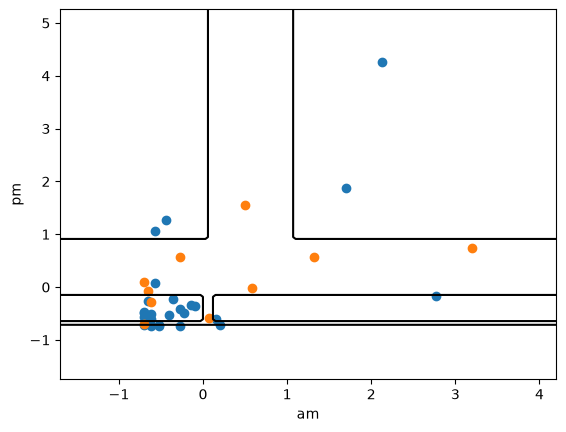

In [176]:
DecisionBoundaryDisplay.from_estimator(
    model_tree,
    tree_df[["am","pm"]],
    response_method="predict_proba",
    plot_method="contour",
    levels=[0.5],
    colors="black",
    ax=plt.gca()
)
working_day = tree_df.loc[tree_df["target"] == 'working day']
weekend_day = tree_df.loc[tree_df["target"] == 'weekend']
plt.scatter(working_day["am"], working_day["pm"], label="working day")
plt.scatter(weekend_day["am"], weekend_day["pm"], label="weekend")

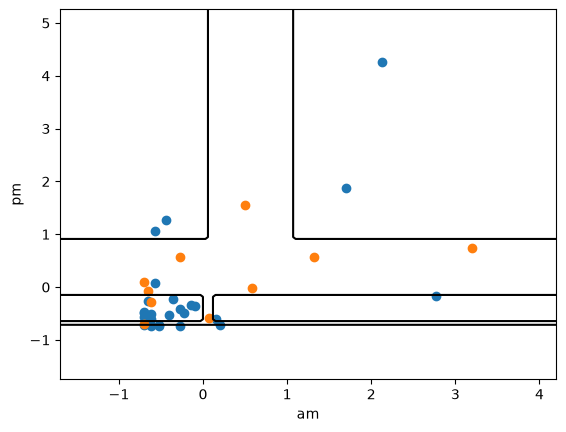

In [177]:
DecisionBoundaryDisplay.from_estimator(
    model_tree,
    tree_df[["am","pm"]],
    response_method="predict_proba",
    plot_method="contour",
    levels=[0.5],
    colors="black",
    ax=plt.gca()
)
working_day = tree_df.loc[tree_df["predict"] == 'working day']
weekend_day = tree_df.loc[tree_df["predict"] == 'weekend']
plt.scatter(working_day["am"], working_day["pm"], label="working day")
plt.scatter(weekend_day["am"], weekend_day["pm"], label="weekend")

[Text(0.4117647058823529, 0.9285714285714286, 'pm <= -0.121\ngini = 0.408\nsamples = 35\nvalue = [10, 25]\nclass = working day'),
 Text(0.11764705882352941, 0.7857142857142857, 'pm <= -0.705\ngini = 0.227\nsamples = 23\nvalue = [3, 20]\nclass = working day'),
 Text(0.2647058823529412, 0.8571428571428572, 'True  '),
 Text(0.058823529411764705, 0.6428571428571429, 'gini = 0.0\nsamples = 6\nvalue = [0, 6]\nclass = working day'),
 Text(0.17647058823529413, 0.6428571428571429, 'pm <= -0.651\ngini = 0.291\nsamples = 17\nvalue = [3, 14]\nclass = working day'),
 Text(0.11764705882352941, 0.5, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]\nclass = weekend'),
 Text(0.23529411764705882, 0.5, 'am <= -0.013\ngini = 0.219\nsamples = 16\nvalue = [2, 14]\nclass = working day'),
 Text(0.11764705882352941, 0.35714285714285715, 'pm <= -0.317\ngini = 0.142\nsamples = 13\nvalue = [1, 12]\nclass = working day'),
 Text(0.058823529411764705, 0.21428571428571427, 'gini = 0.0\nsamples = 10\nvalue = [0, 10]\nclass = 

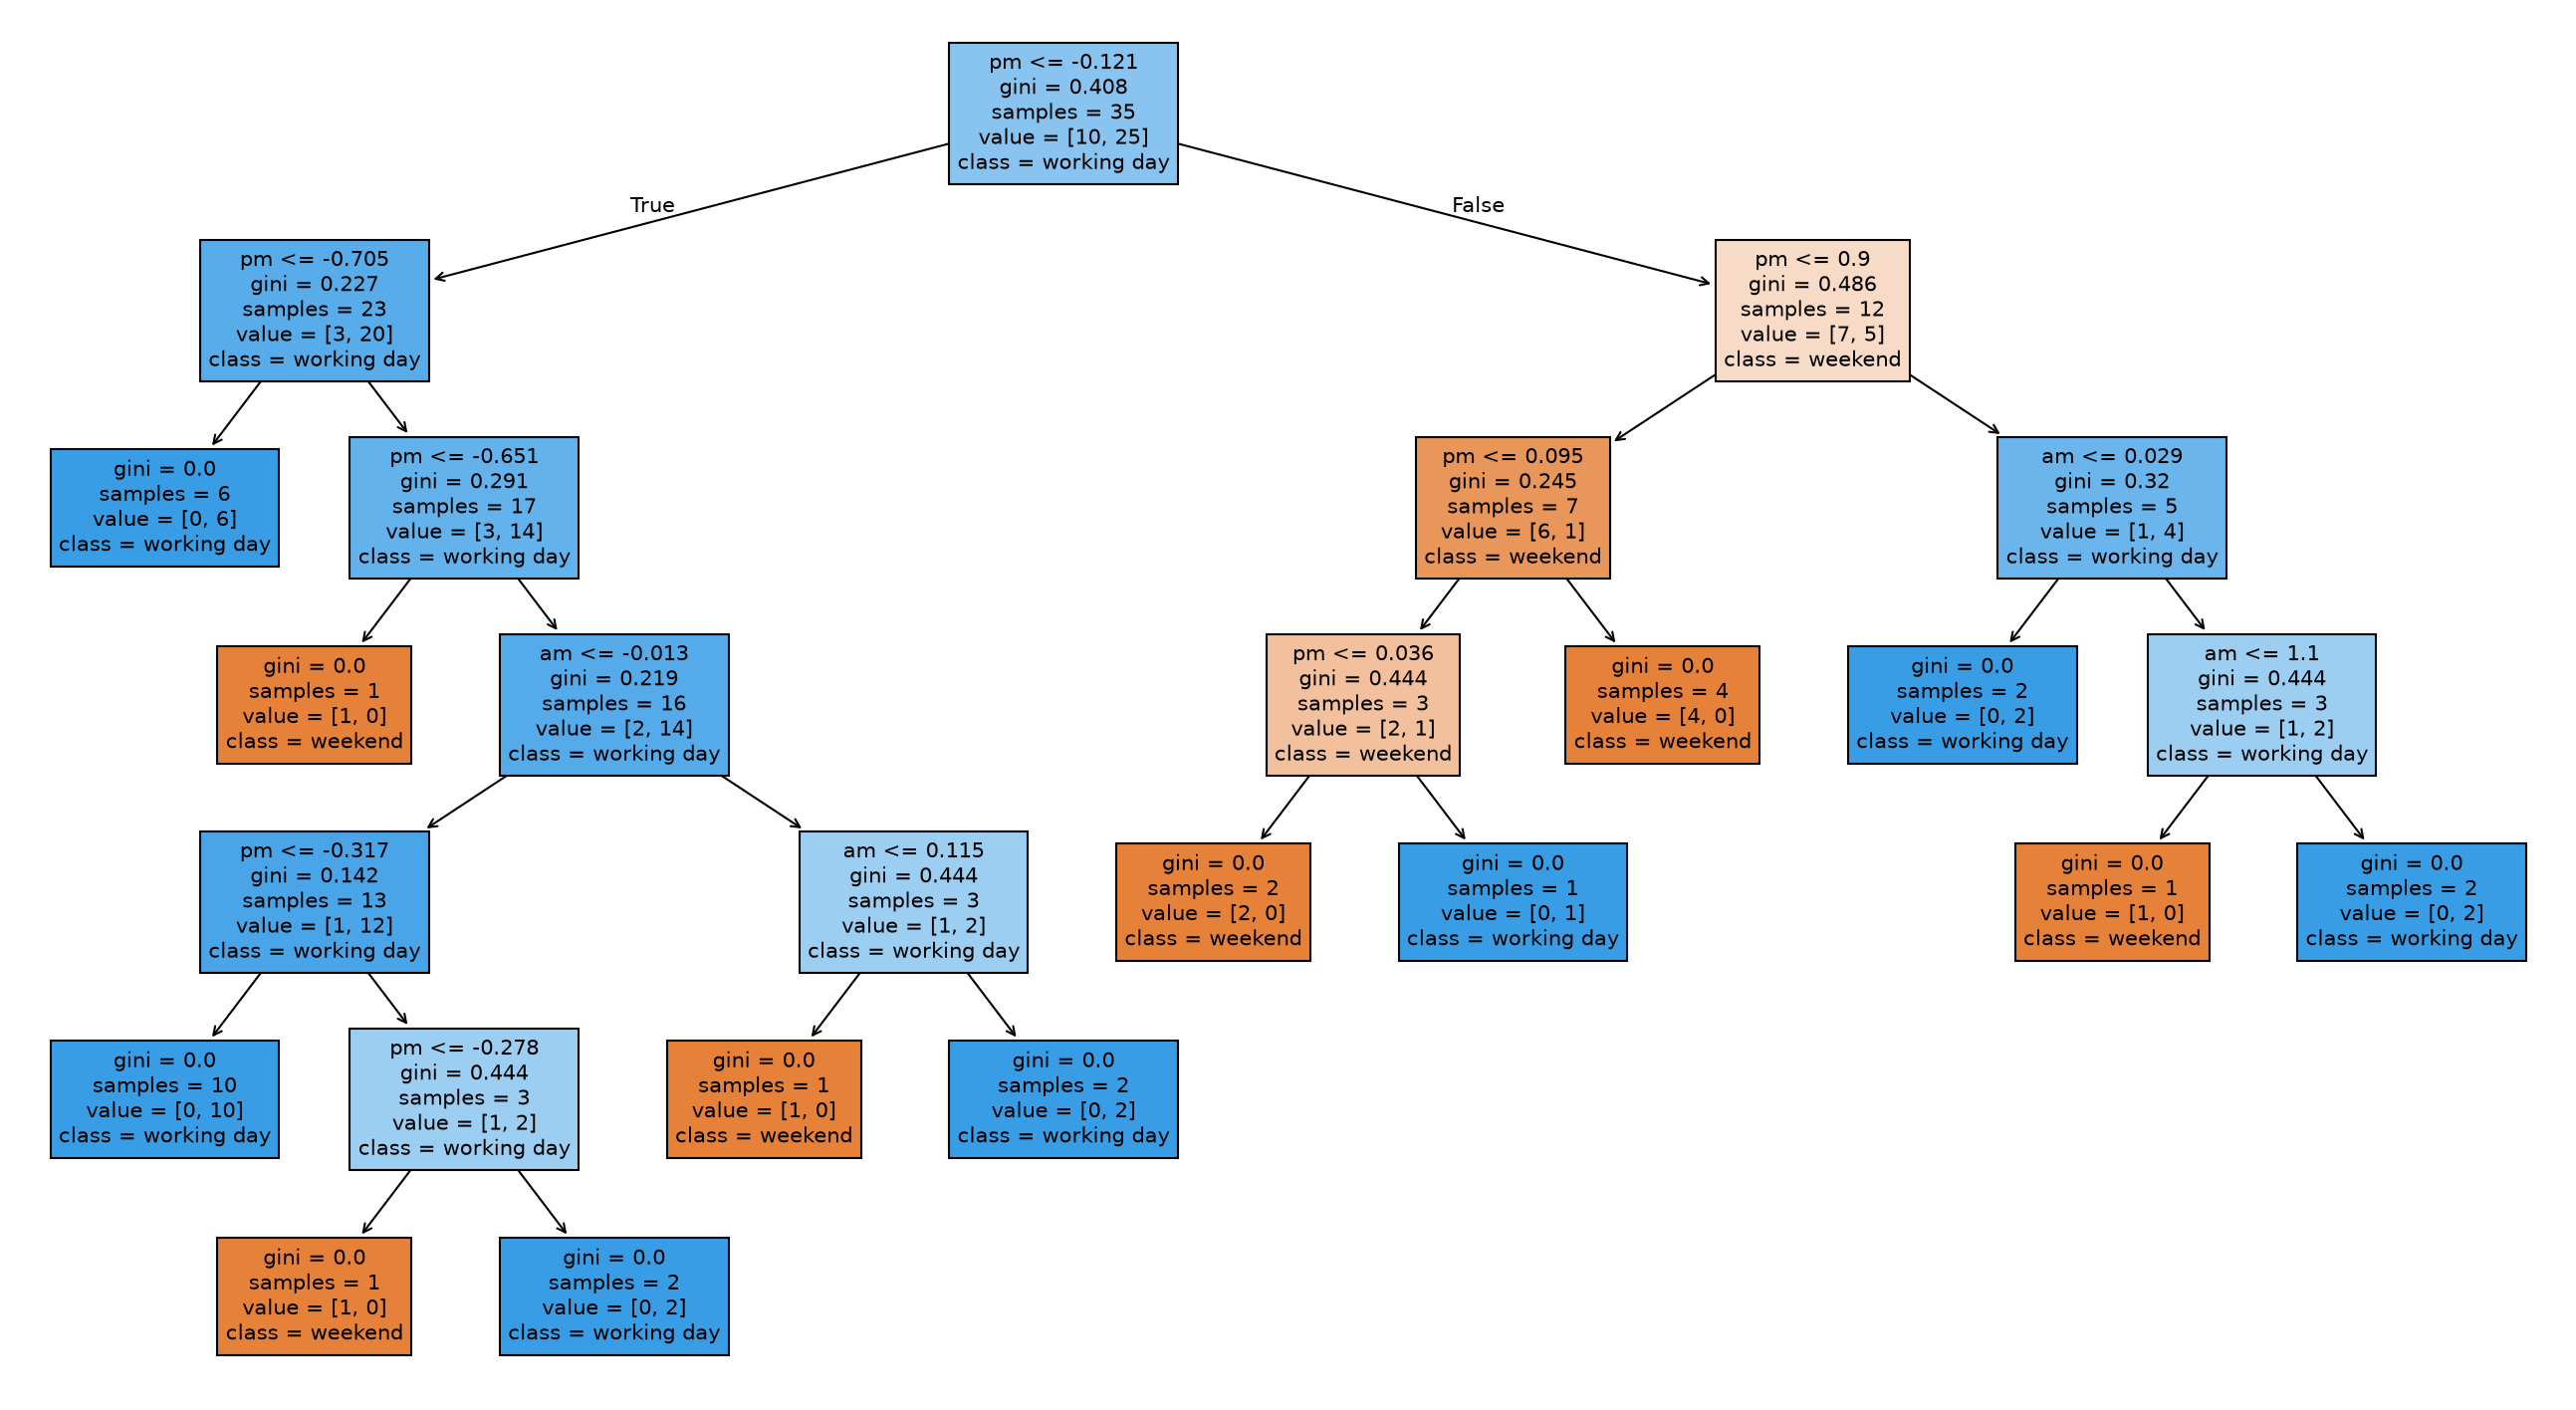

In [189]:
#Смотрим на дерево 
plt.figure(figsize=(22, 12), dpi=150)
plot_tree(
    model_tree,
    feature_names=["am","pm"],
    class_names=model_tree.classes_,
    filled=True,
    fontsize=10
    )

Ответ на вопрос: 7